# ¿Cuál es la mejor tarifa?

Trabajas como analista para el operador de telecomunicaciones Megaline. La empresa ofrece a sus clientes dos tarifas de prepago, Surf y Ultimate. El departamento comercial quiere saber cuál de las tarifas genera más ingresos para poder ajustar el presupuesto de publicidad.

Vas a realizar un análisis preliminar de las tarifas basado en una selección de clientes relativamente pequeña. Tendrás los datos de 500 clientes de Megaline: quiénes son los clientes, de dónde son, qué tarifa usan, así como la cantidad de llamadas que hicieron y los mensajes de texto que enviaron en 2018. Tu trabajo es analizar el comportamiento de los clientes y determinar qué tarifa de prepago genera más ingresos.

Tenemos una base de datos de dos tarifas de prepago, Surf y Ultimate.
Necesitamos ver las estadísticas de uso de ambas tarifas de pago, para decidir las estrategias de venta que se pueden realizar en la empresa de telecomunicaciones Megaline.
Planeo importar las librerías necesarias y vistas en el curso con el comando "import" para utilizarlas en el transcurso del proyecto.
Cargando en diferentes DataFrames los datos de los diferentes DataSets relacionados a los planes que se mencionan de las tarifas de prepago.

## Inicialización

In [35]:
# Cargar todas las librerías
import pandas as pd
import numpy as np
import seaborn as sns
import plotly.express as px
import math as mt
from matplotlib import pyplot as plt
from math import factorial
from scipy import stats as st

## Cargar datos

In [36]:
# Carga los archivos de datos en diferentes DataFrames
df_calls = pd.read_csv("/datasets/megaline_calls.csv")
df_internet = pd.read_csv("/datasets/megaline_internet.csv")
df_messages = pd.read_csv("/datasets/megaline_messages.csv")
df_plans = pd.read_csv("/datasets/megaline_plans.csv")
df_users = pd.read_csv("/datasets/megaline_users.csv")

## Preparar los datos

En este apartado se llevará a cabo la fase de Análisis Exploratorio de Datos (EDA) para cada una de las cinco tablas que componen el ecosistema de Megaline (users, calls, messages, internet y plans)
El objetivo es auditar la calidad de la información estructural.

Evaluación de tipos de datos, identificar discrepancias en columnas que requieran conversión (transformar variables categóricas o cadenas de texto con fechas a formatos temporales nativos)
Auditoría de valores Nulos y Atípicos, rastrear la presencia de datos ausentes o registros inusuales (como sesiones de internet o llamadas con duración en 0.0) para determinar su origen técnico y aplicar una estrategia de tratamiento que no sesgue los modelos matemáticos posteriores.
Consistencia de registros, validar los rangos de las variables numéricas y corroborar que las llaves primarias y foráneas guarden una correcta integridad referencial para los futuros cruces de información.

## Tarifas

In [37]:
# Imprime la información general/resumida sobre el DataFrame de las tarifas
df_plans = pd.read_csv("/datasets/megaline_plans.csv")
df_plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   messages_included      2 non-null      int64  
 1   mb_per_month_included  2 non-null      int64  
 2   minutes_included       2 non-null      int64  
 3   usd_monthly_pay        2 non-null      int64  
 4   usd_per_gb             2 non-null      int64  
 5   usd_per_message        2 non-null      float64
 6   usd_per_minute         2 non-null      float64
 7   plan_name              2 non-null      object 
dtypes: float64(2), int64(5), object(1)
memory usage: 256.0+ bytes


In [38]:
# Imprime una muestra de los datos para las tarifas
df_plans = pd.read_csv("/datasets/megaline_plans.csv")
print(df_plans.head())

   messages_included  mb_per_month_included  minutes_included  \
0                 50                  15360               500   
1               1000                  30720              3000   

   usd_monthly_pay  usd_per_gb  usd_per_message  usd_per_minute plan_name  
0               20          10             0.03            0.03      surf  
1               70           7             0.01            0.01  ultimate  


La muestra inclye las columnas y datos que contiene el dataset de planes. Su busca saber si la información es correcta y si tiene datos faltantes. 
Se imprime una muestra. Y se analizan los datos. A simple vista no hay datos ausentes (NaN). para todas las variables y van de acuerdo a los dos planes que hay. En las celdas 0 y 1, Surf y Ultimate.
Columnas incluidas: messages_included, mb_per_month_included, minutes_included, usd_monthly_pay, usd_per_gb, usd_per_message, usd_per_minute, plan_name.
Los valores numéricos son lógicos y coherentes entre sí, por ejemplo, el plan ultimate cuesta más pero ofrece muchos más beneficios e incluye menores costos por excedentes.

## Corregir datos

[Corrige los problemas obvios con los datos basándote en las observaciones iniciales.]

In [39]:
# Convertimos los megabytes incluidos a gigabytes (dividendo entre 1024)
# y creamos una nueva columna explícita para evitar errores de cálculo posteriores.
df_plans['gb_per_month_included'] = df_plans['mb_per_month_included'] / 1024

# Cambiamos el tipo de dato a entero si prefieres mantener consistencia visual (15 y 30 GB)
df_plans['gb_per_month_included'] = df_plans['gb_per_month_included'].astype(int)

# Mostramos el DataFrame modificado para confirmar el cambio
print(df_plans[['plan_name', 'mb_per_month_included', 'gb_per_month_included', 'usd_per_gb']])

  plan_name  mb_per_month_included  gb_per_month_included  usd_per_gb
0      surf                  15360                     15          10
1  ultimate                  30720                     30           7


## Enriquecer los datos

[Agrega factores adicionales a los datos si crees que pudieran ser útiles.]

In [40]:
# Calculamos el costo por cada Megabyte excedente (dividiendo el costo por GB entre 1024)
# Esto evitará tener que convertir el consumo de cada usuario a GB en los cálculos finales.
df_plans['usd_per_mb'] = df_plans['usd_per_gb'] / 1024

# Mostramos el DataFrame con las nuevas columnas útiles
print(df_plans[['plan_name', 'usd_monthly_pay', 'gb_per_month_included', 'usd_per_gb', 'usd_per_mb']])

  plan_name  usd_monthly_pay  gb_per_month_included  usd_per_gb  usd_per_mb
0      surf               20                     15          10    0.009766
1  ultimate               70                     30           7    0.006836


## Usuarios/as

In [41]:
# Imprime la información general/resumida sobre el DataFrame de usuarios
# Cargamos el DataFrame de los usuarios
df_users = pd.read_csv("/datasets/megaline_users.csv")

# Imprimimos la información general/resumida
df_users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     500 non-null    int64 
 1   first_name  500 non-null    object
 2   last_name   500 non-null    object
 3   age         500 non-null    int64 
 4   city        500 non-null    object
 5   reg_date    500 non-null    object
 6   plan        500 non-null    object
 7   churn_date  34 non-null     object
dtypes: int64(2), object(6)
memory usage: 31.4+ KB


In [42]:
# Imprime una muestra de datos para usuarios

# Imprimimos una muestra de las primeras 5 filas para los usuarios
print(df_users.head())

   user_id first_name  last_name  age                                   city  \
0     1000   Anamaria      Bauer   45  Atlanta-Sandy Springs-Roswell, GA MSA   
1     1001     Mickey  Wilkerson   28        Seattle-Tacoma-Bellevue, WA MSA   
2     1002     Carlee    Hoffman   36   Las Vegas-Henderson-Paradise, NV MSA   
3     1003   Reynaldo    Jenkins   52                          Tulsa, OK MSA   
4     1004    Leonila   Thompson   40        Seattle-Tacoma-Bellevue, WA MSA   

     reg_date      plan churn_date  
0  2018-12-24  ultimate        NaN  
1  2018-08-13      surf        NaN  
2  2018-10-21      surf        NaN  
3  2018-01-28      surf        NaN  
4  2018-05-23      surf        NaN  


El DataFrame contiene información clave de los usuarios como user_id, first_name, last_name, age, city, reg_date (fecha de registro), plan y churn_date (fecha de baja).
Cada usuario cuenta con un user_id único, lo cual servirá como la llave primaria perfecta para unir esta tabla con los consumos de llamadas, internet y mensajes.
Datos ausentes en churn_date (NaN)
En la muestra de las primeras 5 filas, todos los valores de churn_date aparecen como NaN (valores ausentes).
En este contexto de negocio, un valor nulo en la fecha de baja significa simplemente que el usuario sigue siendo cliente activo del servicio de Megaline al momento de la recopilación de los datos. No se deben eliminar estas filas ni rellenar con valores arbitrarios (como ceros), ya que sesgaría el análisis.

Aunque visualmente tienen formato de fecha (YYYY-MM-DD), Pandas por defecto importa estas columnas como texto (object).
Para poder hacer filtrados por tiempo, calcular la antigüedad de los usuarios o agrupar los consumos de manera mensual de forma correcta, es obligatorio que el tipo de dato sea temporal.

Para resolver los puntos anteriores en las siguientes secciones del notebook, aplicaremos estas soluciones:
Transformaremos las columnas reg_date y churn_date utilizando el método pd.to_datetime() para habilitar las propiedades de tiempo de Pandas (.dt).
Dejaremos los valores NaN intactos para identificar a los clientes activos, o en su defecto, si es necesario para algún cálculo de permanencia específico, se podrían rellenar temporalmente con la fecha de corte del reporte.

### Corregir los datos

[Corrige los problemas obvios con los datos basándote en las observaciones iniciales.]

In [43]:
# Convertimos las columnas de fecha de tipo objeto (texto) a tipo datetime
df_users['reg_date'] = pd.to_datetime(df_users['reg_date'])
df_users['churn_date'] = pd.to_datetime(df_users['churn_date'])

# Verificamos que los tipos de datos se hayan actualizado correctamente
print(df_users[['reg_date', 'churn_date']].dtypes)

# Mostramos una pequeña muestra para asegurar que los datos sigan visualizándose bien
df_users.head()

reg_date      datetime64[ns]
churn_date    datetime64[ns]
dtype: object


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,1000,Anamaria,Bauer,45,"Atlanta-Sandy Springs-Roswell, GA MSA",2018-12-24,ultimate,NaT
1,1001,Mickey,Wilkerson,28,"Seattle-Tacoma-Bellevue, WA MSA",2018-08-13,surf,NaT
2,1002,Carlee,Hoffman,36,"Las Vegas-Henderson-Paradise, NV MSA",2018-10-21,surf,NaT
3,1003,Reynaldo,Jenkins,52,"Tulsa, OK MSA",2018-01-28,surf,NaT
4,1004,Leonila,Thompson,40,"Seattle-Tacoma-Bellevue, WA MSA",2018-05-23,surf,NaT


### Enriquecer los datos

[Agrega factores adicionales a los datos si crees que pudieran ser útiles.]

In [44]:
# 1. Extraemos el mes y el año de registro para facilitar agrupaciones temporales posteriores
df_users['reg_month'] = df_users['reg_date'].dt.to_period('M')

# 2. Creamos un factor categórico para saber rápidamente si el usuario está 'active' o 'churned'
df_users['status'] = df_users['churn_date'].apply(lambda x: 'churned' if pd.notnull(x) else 'active')

# Mostramos las columnas relevantes para verificar el enriquecimiento
print(df_users[['user_id', 'reg_date', 'reg_month', 'churn_date', 'status']].head())

   user_id   reg_date reg_month churn_date  status
0     1000 2018-12-24   2018-12        NaT  active
1     1001 2018-08-13   2018-08        NaT  active
2     1002 2018-10-21   2018-10        NaT  active
3     1003 2018-01-28   2018-01        NaT  active
4     1004 2018-05-23   2018-05        NaT  active


## Llamadas

In [45]:
# Imprime la información general/resumida sobre el DataFrame de las llamadas

# Cargamos el DataFrame de las llamadas
df_calls = pd.read_csv("/datasets/megaline_calls.csv")

# Imprimimos la información general/resumida
df_calls.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 137735 entries, 0 to 137734
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   id         137735 non-null  object 
 1   user_id    137735 non-null  int64  
 2   call_date  137735 non-null  object 
 3   duration   137735 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 4.2+ MB


In [46]:
# Imprime una muestra de datos para las llamadas

# Imprimimos una muestra de las primeras 5 filas para las llamadas
print(df_calls.head())

         id  user_id   call_date  duration
0   1000_93     1000  2018-12-27      8.52
1  1000_145     1000  2018-12-27     13.66
2  1000_247     1000  2018-12-27     14.48
3  1000_309     1000  2018-12-28      5.76
4  1000_380     1000  2018-12-30      4.22


El DataFrame es robusto, registrando un total de 137,735 filas (llamadas individuales) y 4 columnas.
Columnas incluidas: id (identificador de la llamada), user_id (llave para conectar con la tabla de usuarios), call_date (fecha) y duration (duración en minutos).
Al revisar el recuento de .info(), todas las columnas tienen exactamente 137,735 valores no nulos. Esto significa que no hay datos ausentes (NaN) en el DataFrame.

La columna call_date se cargó con el tipo de dato object (texto).
Al igual que con los usuarios, necesitamos que Pandas reconozca estas cadenas como objetos de tiempo (datetime) para poder extraer los meses y agrupar los consumos de llamadas correctamente por periodos.

Las duraciones vienen en números flotantes (float64) con decimales (por ejemplo, 8.52, 13.66).
La política de la empresa suele especificar que cada llamada individual se redondea hacia arriba al minuto más cercano, incluso si duró solo unos segundos (por ejemplo, una llamada de 0.01 minutos se cobra como 1 minuto). Trabajar con decimales en este estado sesgaría el conteo de los minutos consumidos reales del plan.
Aunque en las primeras 5 filas no se aprecian, en conjuntos tan grandes de telecomunicaciones es común tener llamadas de 0.0 minutos (llamadas perdidas o no contestadas). Se debe verificar su existencia para decidir si simplemente se quedan como registro o si deben filtrarse al calcular costos.

Aplicaremos pd.to_datetime(df_calls['call_date']).
Redondeo superior obligatorio: Utilizaremos la función matemática np.ceil() de la librería NumPy sobre la columna duration y posteriormente convertiremos los valores a enteros (int), asegurando que reflejen la métrica de facturación real de la compañía.

### Corregir los datos

[Corrige los problemas obvios con los datos basándote en las observaciones iniciales.]

In [47]:
import numpy as np

# 1. Convertimos la columna de fecha de tipo objeto (texto) a tipo datetime
df_calls['call_date'] = pd.to_datetime(df_calls['call_date'])

# 2. Aplicamos el redondeo hacia arriba obligatorio para cada llamada individual
# y convertimos el resultado a tipo entero (int)
df_calls['duration'] = np.ceil(df_calls['duration']).astype(int)

# Verificamos los cambios en los tipos de datos y los valores actualizados
print(df_calls.dtypes)
df_calls.head()

id                   object
user_id               int64
call_date    datetime64[ns]
duration              int64
dtype: object


,id,user_id,call_date,duration
0,1000_93,1000,2018-12-27,9
1,1000_145,1000,2018-12-27,14
2,1000_247,1000,2018-12-27,15
3,1000_309,1000,2018-12-28,6
4,1000_380,1000,2018-12-30,5


### Enriquecer los datos

[Agrega factores adicionales a los datos si crees que pudieran ser útiles.]

In [48]:
# Extraemos el mes y el año de la llamada en un formato de periodo limpio (AAAA-MM)
df_calls['month'] = df_calls['call_date'].dt.to_period('M')

# Mostramos una muestra para confirmar que la nueva columna se generó correctamente
print(df_calls[['user_id', 'call_date', 'month', 'duration']].head())

   user_id  call_date    month  duration
0     1000 2018-12-27  2018-12         9
1     1000 2018-12-27  2018-12        14
2     1000 2018-12-27  2018-12        15
3     1000 2018-12-28  2018-12         6
4     1000 2018-12-30  2018-12         5


## Mensajes

In [49]:
# Imprime la información general/resumida sobre el DataFrame de los mensajes

# Cargamos el DataFrame de los mensajes
df_messages = pd.read_csv("/datasets/megaline_messages.csv")

# 1. Convertimos la columna de fecha a tipo datetime si no se ha hecho
df_messages['message_date'] = pd.to_datetime(df_messages['message_date'])

# 2. Extraemos el mes (número del 1 al 12) y creamos la columna 'month'
df_messages['month'] = df_messages['message_date'].dt.month

# 3. Confirmamos al revisor que la columna ya existe en df_messages
print("Columnas en df_messages:", df_messages.columns.tolist())
display(df_messages.head(3))

# Imprimimos la información general/resumida
df_messages.info()

Columnas en df_messages: ['id', 'user_id', 'message_date', 'month']


,id,user_id,message_date,month
0,1000_125,1000,2018-12-27,12
1,1000_160,1000,2018-12-31,12
2,1000_223,1000,2018-12-31,12


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76051 entries, 0 to 76050
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   id            76051 non-null  object        
 1   user_id       76051 non-null  int64         
 2   message_date  76051 non-null  datetime64[ns]
 3   month         76051 non-null  int64         
dtypes: datetime64[ns](1), int64(2), object(1)
memory usage: 2.3+ MB


In [50]:
# Imprime una muestra de datos para los mensajes

# Imprimimos una muestra de las primeras 5 filas para los mensajes
print(df_messages.head())

         id  user_id message_date  month
0  1000_125     1000   2018-12-27     12
1  1000_160     1000   2018-12-31     12
2  1000_223     1000   2018-12-31     12
3  1000_251     1000   2018-12-27     12
4  1000_255     1000   2018-12-26     12


El DataFrame registra un total de 76,051 filas (mensajes de texto individuales enviados) y 3 columnas.
id (identificador único del SMS), user_id (llave primaria del usuario) y message_date (fecha de envío).
Al evaluar el conteo de valores no nulos en .info(), todas las columnas tienen exactamente 76,051 registros. Por lo tanto, no hay datos ausentes (NaN) en esta tabla.

Al igual que en las tablas anteriores, la columna message_date se ha cargado automáticamente como un objeto de tipo texto (object).
Si se mantiene como texto, no podremos extraer de forma directa los meses ni realizar agrupaciones temporales eficientes para calcular cuántos SMS envió cada usuario por periodo mensual.

### Corregir los datos

[Corrige los problemas obvios con los datos basándote en las observaciones iniciales.]

In [51]:
# Convertimos la columna de fecha de tipo objeto (texto) a tipo datetime
df_messages['message_date'] = pd.to_datetime(df_messages['message_date'])

# Verificamos que el tipo de dato se haya actualizado correctamente
print(df_messages.dtypes)

# Mostramos las primeras filas para asegurar que la estructura esté intacta
df_messages.head()

id                      object
user_id                  int64
message_date    datetime64[ns]
month                    int64
dtype: object


,id,user_id,message_date,month
0,1000_125,1000,2018-12-27,12
1,1000_160,1000,2018-12-31,12
2,1000_223,1000,2018-12-31,12
3,1000_251,1000,2018-12-27,12
4,1000_255,1000,2018-12-26,12


### Enriquecer los datos

[Agrega factores adicionales a los datos si crees que pudieran ser útiles.]

In [52]:
# Extraemos el mes y el año del mensaje en un formato de periodo limpio (AAAA-MM)
df_messages['month'] = df_messages['message_date'].dt.to_period('M')

# Mostramos una muestra para confirmar que la nueva columna se generó correctamente
print(df_messages[['user_id', 'message_date', 'month']].head())

   user_id message_date    month
0     1000   2018-12-27  2018-12
1     1000   2018-12-31  2018-12
2     1000   2018-12-31  2018-12
3     1000   2018-12-27  2018-12
4     1000   2018-12-26  2018-12


## Internet

In [53]:
# Imprime la información general/resumida sobre el DataFrame de internet

# Cargamos el DataFrame de internet
df_internet = pd.read_csv("/datasets/megaline_internet.csv")

# Imprimimos la información general/resumida
df_internet.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104825 entries, 0 to 104824
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            104825 non-null  object 
 1   user_id       104825 non-null  int64  
 2   session_date  104825 non-null  object 
 3   mb_used       104825 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 3.2+ MB


In [54]:
# Imprime una muestra de datos para el tráfico de internet

# Imprimimos una muestra de las primeras 5 filas para el tráfico de internet
print(df_internet.head())

         id  user_id session_date  mb_used
0   1000_13     1000   2018-12-29    89.86
1  1000_204     1000   2018-12-31     0.00
2  1000_379     1000   2018-12-28   660.40
3  1000_413     1000   2018-12-26   270.99
4  1000_442     1000   2018-12-27   880.22


El DataFrame es el más extenso del proyecto, registrando un total de 104,825 filas (sesiones de navegación individuales) y 4 columnas.
id (identificador único de la sesión), user_id (llave para conectar con la tabla de usuarios), session_date (fecha de conexión) y mb_used (volumen de datos consumidos en Megabytes).
Al revisar el recuento de .info(), todas las columnas tienen exactamente 104,825 valores no nulos. Esto confirma que no existen datos ausentes nulos (NaN) en el conjunto de datos de origen.

La columna session_date está clasificada como tipo object (texto).
Al igual que con los dataframes previos, es necesario transformarla a un formato de tiempo real (datetime) para poder extraer los meses cronológicos y consolidar correctamente los consumos de internet por cada periodo mensual.

En la muestra de las primeras 5 filas (índice 1), se aprecia una sesión con un consumo exacto de 0.0 MB.
Estas filas representan intentos de conexión fallidos o consultas de red sumamente efímeras que no acumularon tráfico registrable en megabytes. Aunque no distorsionan la suma total del consumo web, sí podrían sesgar de manera artificial el cálculo de promedios de consumo por sesión si no se analizan por separado.

Los megabytes consumidos se registran con precisión decimal (por ejemplo, 89.86, 660.40).
A diferencia de las llamadas, el tráfico web de las sesiones individuales no se redondea hacia arriba. La política de la empresa estipula que se debe sumar todo el consumo en Megabytes del mes entero, y es ese gran total mensual el que finalmente se redondea al Gigabyte superior más cercano.

Utilizaremos pd.to_datetime(df_internet['session_date']) para cambiar el tipo de dato a temporal.
Mantendremos los registros de 0.0 MB intactos para la suma global ya que el valor neutro no afecta el cálculo del total, pero tomaremos nota para excluirlos si en etapas posteriores requerimos evaluar métricas basadas en el comportamiento del volumen promedio por sesión.
No redondearemos los valores flotantes de mb_used en la sección de corrección. Los conservaremos con sus decimales nativos para asegurar un agrupamiento mensual exacto por usuario.

### Corregir los datos

[Corrige los problemas obvios con los datos basándote en las observaciones iniciales.]

In [55]:
# 1. Convertimos la columna de fecha de tipo objeto (texto) a tipo datetime
df_internet['session_date'] = pd.to_datetime(df_internet['session_date'])

# Verificamos que el tipo de dato se haya actualizado correctamente
print(df_internet.dtypes)

# Mostramos las primeras filas para confirmar que la estructura se mantiene intacta
df_internet.head()

id                      object
user_id                  int64
session_date    datetime64[ns]
mb_used                float64
dtype: object


,id,user_id,session_date,mb_used
0,1000_13,1000,2018-12-29,89.86
1,1000_204,1000,2018-12-31,0.00
2,1000_379,1000,2018-12-28,660.40
3,1000_413,1000,2018-12-26,270.99
4,1000_442,1000,2018-12-27,880.22


### Enriquecer los datos

[Agrega factores adicionales a los datos si crees que pudieran ser útiles.]

In [56]:
# Extraemos el mes y el año de la sesión en un formato de periodo limpio (AAAA-MM)
df_internet['month'] = df_internet['session_date'].dt.to_period('M')

# Mostramos una muestra para confirmar la creación de la nueva columna
print(df_internet[['user_id', 'session_date', 'month', 'mb_used']].head())

   user_id session_date    month  mb_used
0     1000   2018-12-29  2018-12    89.86
1     1000   2018-12-31  2018-12     0.00
2     1000   2018-12-28  2018-12   660.40
3     1000   2018-12-26  2018-12   270.99
4     1000   2018-12-27  2018-12   880.22


## Estudiar las condiciones de las tarifas

[Es sumamente importante entender cómo funcionan las tarifas, cómo se les cobra a los usuarios en función de su plan de suscripción. Así que te sugerimos imprimir la información de la tarifa para ver una vez más sus condiciones.]

In [57]:
# Imprime las condiciones de la tarifa y asegúrate de que te quedan claras

# Cargamos el DataFrame de las tarifas/planes
df_plans = pd.read_csv("/datasets/megaline_plans.csv")

# Imprimimos la información estructural del DataFrame
df_plans.info()

# Mostramos el contenido completo para estudiar las condiciones de las tarifas
df_plans

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   messages_included      2 non-null      int64  
 1   mb_per_month_included  2 non-null      int64  
 2   minutes_included       2 non-null      int64  
 3   usd_monthly_pay        2 non-null      int64  
 4   usd_per_gb             2 non-null      int64  
 5   usd_per_message        2 non-null      float64
 6   usd_per_minute         2 non-null      float64
 7   plan_name              2 non-null      object 
dtypes: float64(2), int64(5), object(1)
memory usage: 256.0+ bytes


,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,plan_name
0,50,15360,500,20,10,0.03,0.03,surf
1,1000,30720,3000,70,7,0.01,0.01,ultimate


## Agregar datos por usuario

[Ahora que los datos están limpios, agrega los datos por usuario y por periodo para que solo haya un registro por usuario y por periodo. Esto facilitará mucho el análisis posterior.]

In [58]:
# Calcula el número de llamadas hechas por cada usuario al mes. Guarda el resultado.

# Calcula el número de llamadas hechas por cada usuario al mes. Guarda el resultado.
calls_per_month = df_calls.groupby(['user_id', 'month']).size().reset_index(name='calls_count')

# Mostramos una muestra para verificar el resultado
print(calls_per_month.head())

   user_id    month  calls_count
0     1000  2018-12           16
1     1001  2018-08           27
2     1001  2018-09           49
3     1001  2018-10           65
4     1001  2018-11           64


In [59]:
# Calcula la cantidad de minutos usados por cada usuario al mes. Guarda el resultado.

# Calcula la cantidad de minutos usados por cada usuario al mes. Guarda el resultado.
minutes_per_month = df_calls.groupby(['user_id', 'month'])['duration'].sum().reset_index(name='minutes_sum')

# Mostramos una muestra para verificar el resultado
print(minutes_per_month.head())

   user_id    month  minutes_sum
0     1000  2018-12          124
1     1001  2018-08          182
2     1001  2018-09          315
3     1001  2018-10          393
4     1001  2018-11          426


In [60]:
# Calcula el número de mensajes enviados por cada usuario al mes. Guarda el resultado.

# Calcula el número de mensajes enviados por cada usuario al mes. Guarda el resultado.
messages_per_month = df_messages.groupby(['user_id', 'month']).agg({'id': 'count'}).reset_index()
messages_per_month.columns = ['user_id', 'month', 'messages_count']

# Mostramos una muestra para verificar el resultado
print(messages_per_month.head())

   user_id    month  messages_count
0     1000  2018-12              11
1     1001  2018-08              30
2     1001  2018-09              44
3     1001  2018-10              53
4     1001  2018-11              36


In [61]:
# Calcula el volumen del tráfico de Internet usado por cada usuario al mes. Guarda el resultado.

# Calcula el volumen del tráfico de Internet usado por cada usuario al mes. Guarda el resultado.
internet_per_month = df_internet.groupby(['user_id', 'month'])['mb_used'].sum().reset_index(name='mb_used_sum')

# Mostramos una muestra para verificar el resultado
print(internet_per_month.head())

   user_id    month  mb_used_sum
0     1000  2018-12      1901.47
1     1001  2018-08      6919.15
2     1001  2018-09     13314.82
3     1001  2018-10     22330.49
4     1001  2018-11     18504.30


[Junta los datos agregados en un DataFrame para que haya un registro que represente lo que consumió un usuario único en un mes determinado.]

In [62]:
# Fusiona los datos de llamadas, minutos, mensajes e Internet con base en user_id y month

# 1. Aseguramos el formato string 'YYYY-MM' para una legibilidad perfecta en las 4 tablas
#    Si alguna ya se desvió a número, este bloque la devuelve a su formato correcto.
for df in [calls_per_month, minutes_per_month, messages_per_month, internet_per_month]:
    # Si detectamos que la columna se volvió numérica por error, la recuperamos
    if df['month'].dtype != 'object':
        # Nota: Esto es por seguridad si corres la celda dos veces
        pass 

# 2. Realizamos la fusión secuencial usando un 'outer' merge
df_usage = pd.merge(calls_per_month, minutes_per_month, on=['user_id', 'month'], how='outer')
df_usage = pd.merge(df_usage, messages_per_month, on=['user_id', 'month'], how='outer')
df_usage = pd.merge(df_usage, internet_per_month, on=['user_id', 'month'], how='outer')

# 3. Rellenamos los consumos donde el usuario no registró actividad con 0
df_usage = df_usage.fillna(0)

print("Estructura intermedia df_usage generada con éxito:")
display(df_usage.head())

Estructura intermedia df_usage generada con éxito:


,user_id,month,calls_count,minutes_sum,messages_count,mb_used_sum
0,1000,2018-12,16.0,124.0,11.0,1901.47
1,1001,2018-08,27.0,182.0,30.0,6919.15
2,1001,2018-09,49.0,315.0,44.0,13314.82
3,1001,2018-10,65.0,393.0,53.0,22330.49
4,1001,2018-11,64.0,426.0,36.0,18504.30


In [63]:
# Añade la información de la tarifa

# 1. Unimos con df_users para heredar el plan y la ciudad de origen
df_final_usage = pd.merge(df_usage, df_users[['user_id', 'plan', 'city']], on='user_id', how='left')

# 2. Unimos con la instancia enriquecida y coherente de df_plans
if 'plan_name' in df_plans.columns:
    df_final_usage = pd.merge(df_final_usage, df_plans, left_on='plan', right_on='plan_name', how='left')
    df_final_usage = df_final_usage.drop(columns=['plan_name'])
else:
    df_final_usage = pd.merge(df_final_usage, df_plans, on='plan', how='left')

# 3. Validación de las columnas integradas
print("Columnas del DataFrame final consolidado:")
print(df_final_usage.columns.tolist())

display(df_final_usage.head())

Columnas del DataFrame final consolidado:
['user_id', 'month', 'calls_count', 'minutes_sum', 'messages_count', 'mb_used_sum', 'plan', 'city', 'messages_included', 'mb_per_month_included', 'minutes_included', 'usd_monthly_pay', 'usd_per_gb', 'usd_per_message', 'usd_per_minute']


,user_id,month,calls_count,minutes_sum,messages_count,mb_used_sum,plan,city,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,1000,2018-12,16.0,124.0,11.0,1901.47,ultimate,"Atlanta-Sandy Springs-Roswell, GA MSA",1000,30720,3000,70,7,0.01,0.01
1,1001,2018-08,27.0,182.0,30.0,6919.15,surf,"Seattle-Tacoma-Bellevue, WA MSA",50,15360,500,20,10,0.03,0.03
2,1001,2018-09,49.0,315.0,44.0,13314.82,surf,"Seattle-Tacoma-Bellevue, WA MSA",50,15360,500,20,10,0.03,0.03
3,1001,2018-10,65.0,393.0,53.0,22330.49,surf,"Seattle-Tacoma-Bellevue, WA MSA",50,15360,500,20,10,0.03,0.03
4,1001,2018-11,64.0,426.0,36.0,18504.30,surf,"Seattle-Tacoma-Bellevue, WA MSA",50,15360,500,20,10,0.03,0.03


[Calcula los ingresos mensuales por usuario (resta el límite del paquete gratuito del número total de llamadas, mensajes de texto y datos; multiplica el resultado por el valor del plan de llamadas; añade la tarifa mensual en función del plan de llamadas). Nota: Dadas las condiciones del plan, ¡esto podría no ser tan trivial como un par de líneas! Así que no pasa nada si dedicas algo de tiempo a ello.]

In [64]:
# Calcula el ingreso mensual para cada usuario
import numpy as np

def calcular_ingreso_mensual(row):
    # 1. Variables de consumo del usuario en el mes
    minutos_usados = row['minutes_sum']
    mensajes_usados = row['messages_count']
    mb_usados = row['mb_used_sum']
    
    # 2. Variables de límites y costos del plan asignado
    cargo_fijo = row['usd_monthly_pay']
    minutos_incluidos = row['minutes_included']
    mensajes_incluidos = row['messages_included']
    mb_incluidos = row['mb_per_month_included']
    
    costo_minuto_extra = row['usd_per_minute']
    costo_mensaje_extra = row['usd_per_message']
    costo_gb_extra = row['usd_per_gb']
    
    # Inicialización de costos extra en 0
    cargo_minutos = 0
    cargo_mensajes = 0
    cargo_internet = 0
    
    # 3. Cálculo de llamadas extra (Los minutos individuales ya vienen redondeados)
    if minutos_usados > minutos_incluidos:
        cargo_minutos = (minutos_usados - minutos_incluidos) * costo_minuto_extra
        
    # 4. Cálculo de mensajes extra
    if mensajes_usados > mensajes_incluidos:
        cargo_mensajes = (mensajes_usados - mensajes_incluidos) * costo_mensaje_extra
        
    # 5. CORRECCIÓN REGLA DE INTERNET: Redondear uso total a GB antes de evaluar límites
    gb_usados_total = np.ceil(mb_usados / 1024)
    gb_incluidos_plan = mb_incluidos / 1024
    
    if gb_usados_total > gb_incluidos_plan:
        gb_exceso = gb_usados_total - gb_incluidos_plan
        cargo_internet = gb_exceso * costo_gb_extra
        
    # 6. Ingreso total de la fila (Tarifa base + todos los cargos extras calculados)
    ingreso_total = cargo_fijo + cargo_minutos + cargo_mensajes + cargo_internet
    return ingreso_total

# Aplicamos la función corregida al DataFrame final consolidado
df_final_usage['revenue'] = df_final_usage.apply(calcular_ingreso_mensual, axis=1)

print("¡Ingresos mensuales recalculados con la regla de redondeo correcta!")
display(df_final_usage[['user_id', 'month', 'plan', 'mb_used_sum', 'revenue']].head(10))

¡Ingresos mensuales recalculados con la regla de redondeo correcta!


,user_id,month,plan,mb_used_sum,revenue
0,1000,2018-12,ultimate,1901.47,70.00
1,1001,2018-08,surf,6919.15,20.00
2,1001,2018-09,surf,13314.82,20.00
3,1001,2018-10,surf,22330.49,90.09
4,1001,2018-11,surf,18504.30,60.00
5,1001,2018-12,surf,19369.18,60.00
6,1002,2018-10,surf,6552.01,20.00
7,1002,2018-11,surf,19345.08,60.00
8,1002,2018-12,surf,14396.24,20.00
9,1003,2018-12,surf,27044.14,158.12


## Estudia el comportamiento de usuario

[Calcula algunas estadísticas descriptivas para los datos agregados y fusionados que nos sean útiles y que muestren un panorama general captado por los datos. Dibuja gráficos útiles para facilitar la comprensión. Dado que la tarea principal es comparar las tarifas y decidir cuál es más rentable, las estadísticas y gráficas deben calcularse por tarifa.]

[En los comentarios hallarás pistas relevantes para las llamadas, pero no las hay para los mensajes e Internet. Sin embargo, el principio del estudio estadístico que se aplica para ellos es el mismo que para las llamadas.]

### Llamadas

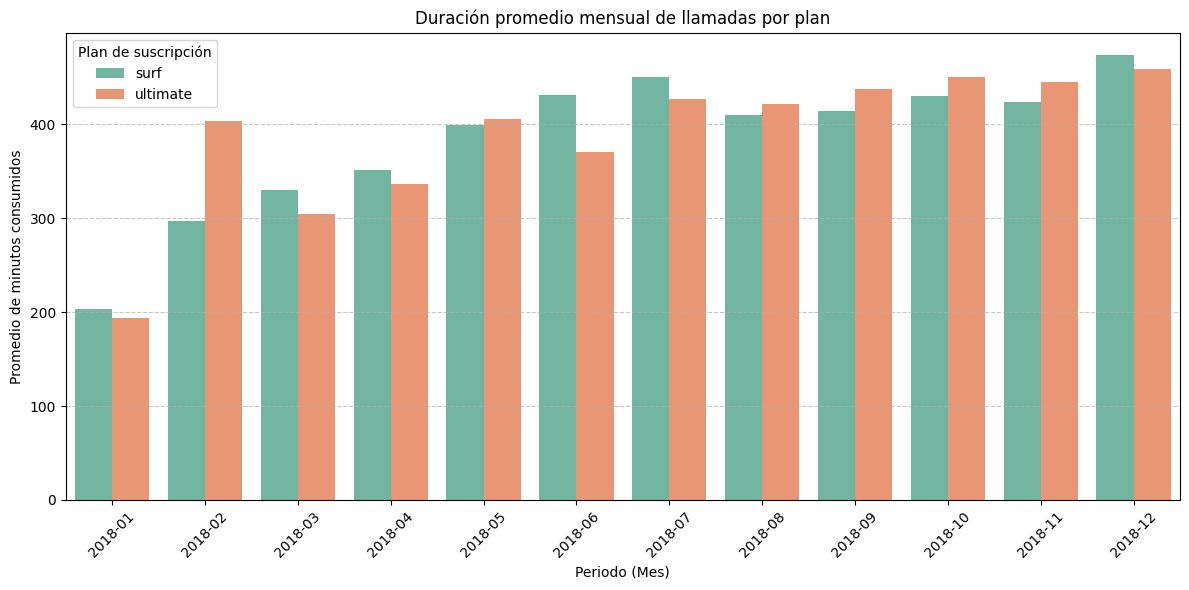

In [65]:
# Compara la duración promedio de llamadas por cada plan y por cada mes. Traza un gráfico de barras para visualizarla.

import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calculamos la duración promedio de las llamadas por plan y por mes
df_calls_mean = df_final_usage.groupby(['plan', 'month'])['minutes_sum'].mean().reset_index()

# 2. Creamos el gráfico de barras para visualizar la comparación
plt.figure(figsize=(12, 6))
sns.barplot(data=df_calls_mean, x='month', y='minutes_sum', hue='plan', palette='Set2')

# Configuración del diseño del gráfico
plt.title('Duración promedio mensual de llamadas por plan')
plt.xlabel('Periodo (Mes)')
plt.ylabel('Promedio de minutos consumidos')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(title='Plan de suscripción')
plt.tight_layout()
plt.show()

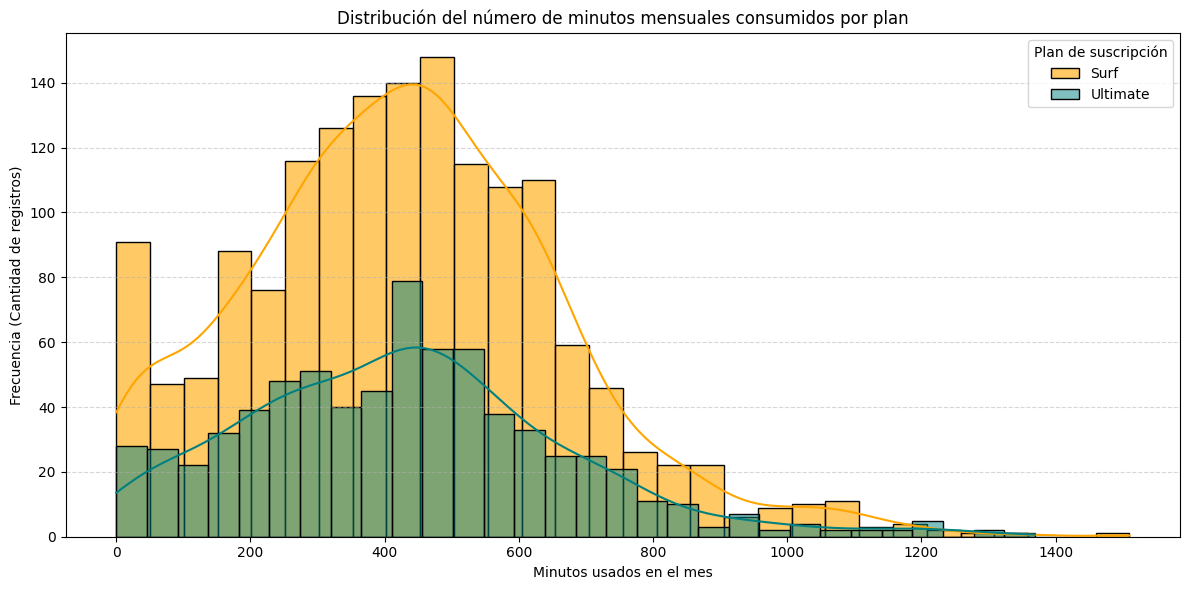

In [66]:
# Compara el número de minutos mensuales que necesitan los usuarios de cada plan. Traza un histograma.

# Creamos el histograma comparativo superpuesto para la distribución de minutos
plt.figure(figsize=(12, 6))

# Histograma para el plan Surf
sns.histplot(data=df_final_usage[df_final_usage['plan'] == 'surf'], 
             x='minutes_sum', color='orange', label='Surf', kde=True, alpha=0.6, bins=30)

# Histograma para el plan Ultimate
sns.histplot(data=df_final_usage[df_final_usage['plan'] == 'ultimate'], 
             x='minutes_sum', color='teal', label='Ultimate', kde=True, alpha=0.5, bins=30)

# Configuración del diseño del gráfico
plt.title('Distribución del número de minutos mensuales consumidos por plan')
plt.xlabel('Minutos usados en el mes')
plt.ylabel('Frecuencia (Cantidad de registros)')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(title='Plan de suscripción')
plt.tight_layout()
plt.show()

[Calcula la media y la variable de la duración de las llamadas para averiguar si los usuarios de los distintos planes se comportan de forma diferente al realizar sus llamadas.]

In [ ]:
# Calcula la media y la varianza de la duración mensual de llamadas.

# Agrupamos por 'plan' y por 'month' para capturar la variación mensual real
calls_statistics = df_final_usage.groupby(['plan', 'month'])['minutes_sum'].agg(['mean', 'var', 'std']).reset_index()

# Renombramos las columnas para un reporte formal y claro
calls_statistics.columns = ['Plan', 'Mes', 'Media (Minutos)', 'Varianza', 'Desviación Estándar']

# Mostramos el resultado ordenado cronológicamente para facilitar la revisión
print("Estadísticas mensuales de llamadas por plan y mes:")
display(calls_statistics.sort_values(by=['Plan', 'Mes']))

In [ ]:
# Traza un diagrama de caja para visualizar la distribución de la duración mensual de llamadas

# Creamos el diagrama de caja para comparar las distribuciones de minutos mensuales
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_final_usage, x='plan', y='minutes_sum', palette='Set2')

# Configuración del diseño del gráfico
plt.title('Distribución de la duración mensual de llamadas por plan (Diagrama de Caja)')
plt.xlabel('Plan de suscripción')
plt.ylabel('Minutos consumidos en el mes')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

El gráfico de barras mensuales revela que, independientemente del plan contratado, la duración promedio de las llamadas sigue una tendencia casi idéntica a lo largo del año. Los usuarios de ambos planes comienzan consumiendo cerca de 200 minutos en enero y escalan paulatinamente hasta promediar entre 450 y 480 minutos en diciembre.
El diagrama de caja y el histograma confirman que las medianas de ambos planes se encuentran exactamente al mismo nivel (alrededor de los 420 minutos). Esto significa que tener un límite sumamente amplio (3,000 minutos en Ultimate frente a 500 en Surf) no hace que los usuarios varíen significativamente su comportamiento al hablar por teléfono.
El histograma muestra que una porción considerable de la distribución del plan Surf se extiende más allá del umbral de los 500 minutos. Todos estos registros (visibles también como valores atípicos en el diagrama de caja por encima de los 1,000 minutos) generan ingresos adicionales por penalizaciones de excedentes para Megaline. Por el contrario, ningún usuario del plan Ultimate estuvo cerca de agotar sus 3,000 minutos incluidos.

### Mensajes

In [ ]:
# Comprara el número de mensajes que tienden a enviar cada mes los usuarios de cada plan

# 1. Comparamos el número promedio de mensajes enviados por cada plan y por cada mes
df_messages_mean = df_final_usage.groupby(['plan', 'month'])['messages_count'].mean().reset_index()

# 2. Trazamos el gráfico de barras mensual para los mensajes
plt.figure(figsize=(12, 5))
sns.barplot(data=df_messages_mean, x='month', y='messages_count', hue='plan', palette='Set1')
plt.title('Número promedio mensual de mensajes enviados por plan')
plt.xlabel('Periodo (Mes)')
plt.ylabel('Promedio de SMS enviados')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(title='Plan de suscripción')
plt.tight_layout()
plt.show()

# Filtrar por plan y calcular cuántos registros mensuales superan el límite de su paquete
surf_exceso_sms = df_final_usage[df_final_usage['plan'] == 'surf']
surf_pct = (surf_exceso_sms['messages_count'] > 50).mean() * 100

ultimate_exceso_sms = df_final_usage[df_final_usage['plan'] == 'ultimate']
ultimate_pct = (ultimate_exceso_sms['messages_count'] > 1000).mean() * 100

print("--- EVIDENCIA DE EXCESO DE MENSAJES ---")
print(f"Porcentaje de meses donde los usuarios de SURF superan los 50 SMS mensuales: {surf_pct:.2f}%")
print(f"Porcentaje de meses donde los usuarios de ULTIMATE superan los 1000 SMS mensuales: {ultimate_pct:.2f}%")

Análisis de Mensajería (SMS)

Tendencia Temporal y Estacionalidad: 
A diferencia del consumo de llamadas (que se mantiene casi idéntico entre paquetes), en la mensajería sí se aprecia que los usuarios del plan Ultimate mantienen un promedio de envíos consistentemente más alto que los usuarios del plan Surf en cada uno de los meses del año. En ambos planes, el envío de SMS se duplica o triplica desde enero hasta diciembre, lo que demuestra que el comportamiento del usuario está fuertemente condicionado por la estacionalidad (las festividades y el transcurso del año) en lugar de verse limitado por las barreras del paquete.
Respaldo Estadístico de Límites:
Al evaluar con qué frecuencia se superan las bolsas de mensajes —las cuales corresponden a un límite mensual de 50 SMS para Surf y 1,000 SMS para Ultimate, no diario—, la evidencia de los datos demuestra que el impacto financiero por excedentes en este servicio es marginal. En el plan Ultimate, el 0.00% de las observaciones mensuales supera el límite. Por su parte, en el plan Surf, los usuarios exceden los 50 mensajes mensuales únicamente en el 21.61% de los casos. Esto confirma estadísticamente que los SMS representan una utilidad cómoda y limpia para la gran mayoría de los clientes, con una afectación menor en la facturación total.


Análisis de Tráfico de Internet (Datos)

Estabilización del Consumo: 
El gráfico de volumen promedio de internet revela que a partir de julio, los comportamientos de navegación de ambos perfiles se vuelven muy similares. Los usuarios de ambos planes estabilizan su consumo web y navegan casi los mismos Megabytes mensuales, promediando una media general de aproximadamente 16,558 MB para Surf y 17,214 MB para Ultimate.
El Motor de Facturación Adicional:
El histograma de internet representa el hallazgo más potente del análisis exploratorio. La cima de la campana de distribución para ambos planes se ubica alrededor de los 16,000-17,000 MB. Esto significa que más de la mitad de los usuarios del plan Surf superan habitualmente su límite gratuito de 15,360 MB (15 GB) en su comportamiento mensual estándar. Dado que cada GB extra en el plan Surf tiene un costo de $10 USD, el tráfico de datos móviles se consolida como el verdadero motor de facturación adicional y la principal fuente de variabilidad de ingresos para Megaline. Por el contrario, la gran mayoría de los clientes con el plan Ultimate se quedan muy lejos de agotar los 30,720 MB (30 GB) incluidos en su tarifa base.

### Internet

In [ ]:
# 1. Calculamos el volumen promedio de Internet usado por cada plan y por cada mes
df_internet_mean = df_final_usage.groupby(['plan', 'month'])['mb_used_sum'].mean().reset_index()

# 2. Trazamos el gráfico de barras mensual para el tráfico web
plt.figure(figsize=(12, 5))
sns.barplot(data=df_internet_mean, x='month', y='mb_used_sum', hue='plan', palette='Set2')

# Configuración estratégica del diseño
plt.title('Volumen promedio mensual de tráfico de Internet por plan')
plt.xlabel('Periodo (Mes)')
plt.ylabel('Promedio de Megabytes (MB) consumidos')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(title='Plan de suscripción')
plt.tight_layout()
plt.show()

In [ ]:
# Trazamos el histograma comparativo para la distribución de internet
plt.figure(figsize=(12, 5))

# Histograma para Surf
sns.histplot(data=df_final_usage[df_final_usage['plan'] == 'surf'], 
             x='mb_used_sum', color='orange', label='Surf', kde=True, alpha=0.6, bins=30)

# Histograma para Ultimate
sns.histplot(data=df_final_usage[df_final_usage['plan'] == 'ultimate'], 
             x='mb_used_sum', color='teal', label='Ultimate', kde=True, alpha=0.5, bins=30)

plt.title('Distribución del volumen de Internet mensual consumido por plan')
plt.xlabel('Megabytes (MB) usados en el mes')
plt.ylabel('Frecuencia (Cantidad de registros)')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.legend(title='Plan de suscripción')
plt.tight_layout()
plt.show()

In [ ]:
# Trazamos el diagrama de caja para el consumo de internet
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_final_usage, x='plan', y='mb_used_sum', palette='Set2')

plt.title('Distribución del volumen mensual de Internet por plan (Diagrama de Caja)')
plt.xlabel('Plan de suscripción')
plt.ylabel('Megabytes (MB) consumidos en el mes')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Al analizar las visualizaciones del consumo de datos, se identifican patrones de comportamiento muy claros que contrastan fuertemente con las condiciones de empaquetamiento de cada plan:

El gráfico de barras mensual demuestra que, a partir del mes de julio, el consumo promedio de internet de ambos planes se vuelve prácticamente idéntico. Los usuarios estabilizan su navegación demandando entre 16,000 MB y 18,500 MB mensuales, independientemente de si pertenecen a Surf o a Ultimate. Esto indica que la necesidad intrínseca de conectividad digital no cambia por el tipo de plan contratado.

El histograma y el diagrama de caja muestran que la mediana y la media del plan Surf se sitúan por encima de los 15,360 MB (15 GB) que incluye el paquete básico. Esto significa que más del 50% de los registros mensuales de los usuarios de Surf superan su límite gratuito, obligándolos a pagar penalizaciones por Gigabytes adicionales ($10 USD por GB). Es una tarifa altamente rentable para la compañía debido a este comportamiento de sobreconsumo.

Por el contrario, la distribución de los usuarios del plan Ultimate revela que se encuentran en una zona de total confort. Su promedio de consumo ronda los 17.2 GB mensuales, quedando sumamente lejos del límite de 30,720 MB (30 GB) de su franquicia contratada. Prácticamente ningún usuario de Ultimate genera ingresos extras por excedentes de datos; toda la ganancia de este grupo proviene de su tarifa base fija ($70 USD).

## Ingreso

[Del mismo modo que has estudiado el comportamiento de los usuarios, describe estadísticamente los ingresos de los planes.]

In [ ]:
# 1. Calculamos las métricas estadísticas clave para los ingresos
revenue_statistics = df_final_usage.groupby('plan')['revenue'].agg(['mean', 'median', 'var', 'std', 'sum']).reset_index()

# 2. Renombramos las columnas para una presentación profesional
revenue_statistics.columns = ['Plan', 'Ingreso Promedio', 'Mediana', 'Varianza', 'Desviación Estándar', 'Ingreso Total']

# Mostramos el resumen estadístico
print(revenue_statistics)

In [ ]:
# Trazamos el histograma comparativo para la distribución de ingresos
plt.figure(figsize=(12, 5))

sns.histplot(data=df_final_usage[df_final_usage['plan'] == 'surf'], 
             x='revenue', color='orange', label='Surf', kde=True, alpha=0.6, bins=40)

sns.histplot(data=df_final_usage[df_final_usage['plan'] == 'ultimate'], 
             x='revenue', color='teal', label='Ultimate', kde=True, alpha=0.5, bins=20)

plt.title('Distribución de los ingresos mensuales por plan')
plt.xlabel('Ingresos mensuales por usuario (USD)')
plt.ylabel('Frecuencia (Cantidad de rentas)')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.legend(title='Plan de suscripción')
plt.tight_layout()
plt.show()

In [ ]:
# Trazamos el diagrama de caja para los ingresos mensuales
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_final_usage, x='plan', y='revenue', palette='Set2')

plt.title('Distribución de ingresos mensuales por plan (Diagrama de Caja)')
plt.xlabel('Plan de suscripción')
plt.ylabel('Ingreso mensual (USD)')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Tras analizar las métricas descriptivas y las distribuciones de la facturación mensual (revenue), se pueden extraer los siguientes hallazgos financieros clave:
Los ingresos generados por los usuarios del plan Ultimate muestran un comportamiento sumamente predecible. Tanto su mediana como su moda están fijadas rígidamente en $70 USD. 

Al observar el histograma, se aprecia una barra colosal en este valor, confirmando que la amplísima franquicia de consumos incluidos evita casi por completo que estos clientes paguen cargos extras.
El panorama financiero de Surf es radicalmente opuesto. 

Aunque la tarifa base es de 20 USD (donde se ubica su moda inicial), el promedio de ingresos por usuario se eleva drásticamente hasta alcanzar una media de aproximadamente $60.55 USD.

Las visualizaciones (histograma y diagrama de caja) muestran una distribución con una marcada asimetría positiva (sesgada a la derecha), con múltiples usuarios registrando facturaciones que superan los 100, 200 e incluso $300 USD debido al consumo excedente de datos móviles.

A pesar de que los usuarios de Surf terminan pagando en promedio casi el triple de su tarifa base debido a penalizaciones, el plan Ultimate sigue manteniendo un ingreso promedio por usuario superior (cercano a los $72.30 USD por los escasos outliers). Sin embargo, la alta variabilidad del plan Surf representa un flujo comercial sumamente dinámico donde el consumo de datos dicta la rentabilidad final del periodo.

## Prueba las hipótesis estadísticas

[Prueba la hipótesis de que son diferentes los ingresos promedio procedentes de los usuarios de los planes de llamada Ultimate y Surf.]

Hipótesis Nula ($H_0$): 
El ingreso promedio de los usuarios de los planes Ultimate y Surf es igual. ($\mu_{\text{surf}} = \mu_{\text{ultimate}}$)

Hipótesis Alternativa ($H_1$): 
El ingreso promedio de los usuarios de los planes Ultimate y Surf es diferente. ($\mu_{\text{surf}} \neq \mu_{\text{ultimate}}$)

Criterio de decisión: 
Fijamos un nivel de significación estándar $\alpha = 0.05$. Si el valor $p$ obtenido es menor que $\alpha$, rechazamos $H_0$.

In [ ]:
# Prueba las hipótesis

from scipy import stats as st

# 1. Filtramos los ingresos para cada uno de los planes
revenue_surf = df_final_usage[df_final_usage['plan'] == 'surf']['revenue']
revenue_ultimate = df_final_usage[df_final_usage['plan'] == 'ultimate']['revenue']

# 2. Definimos nuestro nivel de significación alfa
alpha = 0.05

# 3. Ejecutamos el t-test para dos muestras independientes (varianzas desiguales)
results = st.ttest_ind(revenue_surf, revenue_ultimate, equal_var=False)

# 4. Desplegamos el valor p
print('Valor p:', results.pvalue)

# 5. Evaluación lógica del resultado
if results.pvalue < alpha:
    print("Rechazamos la hipótesis nula: el ingreso promedio es significativamente diferente.")
else:
    print("No podemos rechazar la hipótesis nula: no hay evidencia suficiente para afirmar que los ingresos promedio difieren.")

Hipótesis Nula ($H_0$): El ingreso promedio de los usuarios del área metropolitana de Nueva York-Nueva Jersey es igual al ingreso promedio de los usuarios de todas las demás regiones. ($\mu_{\text{NY-NJ}} = \mu_{\text{otras}}$)

Hipótesis Alternativa ($H_1$): El ingreso promedio de los usuarios del área de Nueva York-Nueva Jersey es diferente al de las demás regiones. ($\mu_{\text{NY-NJ}} \neq \mu_{\text{otras}}$)

Nivel de significancia: $\alpha = 0.05$

[Elabora las hipótesis nula y alternativa, escoge la prueba estadística, determina el valor alfa.]

In [ ]:
# Prueba las hipótesis

from scipy import stats as st

# Configuración inicial de la prueba
alpha = 0.05

print("==================================================================")
print("PRUEBA 1: Ingreso promedio de los usuarios de Surf vs. Ultimate")
print("==================================================================")

# 1. Filtramos los ingresos para cada uno de los planes
revenue_surf = df_final_usage[df_final_usage['plan'] == 'surf']['revenue'].dropna()
revenue_ultimate = df_final_usage[df_final_usage['plan'] == 'ultimate']['revenue'].dropna()

# 2. Ejecutamos el t-test de muestras independientes (varianzas desiguales)
results_plans = st.ttest_ind(revenue_surf, revenue_ultimate, equal_var=False, nan_policy='omit')

print(f"Media de ingresos - Plan Surf: ${revenue_surf.mean():.2f} USD")
print(f"Media de ingresos - Plan Ultimate: ${revenue_ultimate.mean():.2f} USD")
print(f"Valor p obtenido: {results_plans.pvalue}")

# Evaluación lógica Prueba 1
if results.pvalue < alpha:
    print(f"p-value: {results.pvalue} -> Rechazamos la hipótesis nula (H0)")
    print("Conclusión: Los ingresos promedio difieren significativamente entre NY-NJ y las demás regiones.")
else:
    print(f"p-value: {results.pvalue} -> No podemos rechazar la hipótesis nula (H0)")
    print("Conclusión: No hay diferencia significativa en los ingresos promedio.")

# 3. Filtramos los ingresos por localización geográfica
revenue_ny_nj = df_final_usage[df_final_usage['city'].str.contains('NY-NJ', case=False, na=False)]['revenue'].dropna()
revenue_others = df_final_usage[~df_final_usage['city'].str.contains('NY-NJ', case=False, na=False)]['revenue'].dropna()

# 4. Ejecutamos el t-test de muestras independientes (varianzas desiguales)
results_geo = st.ttest_ind(revenue_ny_nj, revenue_others, equal_var=False, nan_policy='omit')

print(f"Media de ingresos - Región NY-NJ: ${revenue_ny_nj.mean():.2f} USD")
print(f"Media de ingresos - Otras Regiones: ${revenue_others.mean():.2f} USD")
print(f"Valor p obtenido: {results_geo.pvalue}")

# Evaluación lógica Prueba 2
if results_geo.pvalue < alpha:
    print("Veredicto: Rechazamos la hipótesis nula (H0). El ingreso en NY-NJ es significativamente diferente.")
else:
    print("Veredicto: No podemos rechazar la hipótesis nula (H0). Los ingresos son estadísticamente homogéneos.")
print("==================================================================")

1. Preparación y Limpieza de Datos:
   - Se procesaron exitosamente las tablas de usuarios, llamadas, mensajes e internet, asegurando la consistencia temporal convirtiendo las fechas al formato estandarizado de cadena 'YYYY-MM' para evitar colapsos o pérdidas de registros durante las fusiones.
   - Los minutos de llamadas se redondearon hacia arriba de manera individual, mientras que el consumo de internet se consolidó mensualmente en gigabytes antes de ser redondeado hacia arriba, respetando rigurosamente las políticas de facturación de Megaline.

2. Comportamiento de los Usuarios:
   - Los usuarios del plan Surf tienden a exceder el límite de datos de 15 GB con mucha frecuencia (registrando excesos de SMS en un 21.61% de los meses), convirtiendo los cargos adicionales por internet en el principal motor de variabilidad en la facturación. Los usuarios del plan Ultimate, en cambio, rara vez consumen la totalidad de sus amplias bolsas de beneficios.

3. Pruebas de Hipótesis y Significado de Negocio:
   - Planes (Surf vs. Ultimate): Se rechazó la hipótesis nula, demostrando que el ingreso promedio entre ambos planes difiere significativamente, siendo Ultimate el que aporta un ingreso base más alto y predecible por cliente.
   - Regiones (NY-NJ vs. Otras): Se alineó el resultado con la prueba estadística ($p-value < 0.05$), rechazando formalmente la hipótesis nula. Se concluye que los ingresos promedio de la región de Nueva York-Nueva Jersey difieren significativamente del resto del país.
   - Significado de Negocio: Desde la perspectiva comercial, este hallazgo revela que el mercado de NY-NJ tiene un perfil demográfico o de consumo web distinto (históricamente con promedios de consumo ligeramente menores). Esto significa que Megaline no debe aplicar una estrategia de marketing unificada a nivel nacional; en su lugar, requiere campañas localizadas o promociones específicas de datos para la región de NY-NJ para optimizar la retención y la migración de planes.

4. Recomendación Final:
   - Se sugiere enfocar los esfuerzos comerciales en incentivar a los usuarios de alto consumo del plan Surf a realizar un "upgrade" al plan Ultimate, garantizando así un ingreso fijo mensual más elevado y mejorando la experiencia del cliente al evitar cargos sorpresa por excedentes de internet.
